In [1]:
import sys
sys.path.append("..")

from pathlib import Path
import numpy as np
import pandas as pd

from src.credit.features import TARGET, build_features

DATA_DIR = Path("../data/raw")
df = pd.read_csv(DATA_DIR / "application_train.csv")

X = build_features(df)
y = df[TARGET]
X.shape, y.shape, y.mean()

((307511, 92), (307511,), np.float64(0.08072881945686496))

In [2]:
numeric_cols = X.select_dtypes("number").columns.tolist()
categorical_cols = X.select_dtypes("object").columns.tolist()
len(numeric_cols), len(categorical_cols)

C:\Users\ibrah\AppData\Local\Temp\ipykernel_6768\2564670927.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes("object").columns.tolist()


(77, 15)

In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42,
)
y_train.mean(), y_test.mean()

(np.float64(0.08072908198107379), np.float64(0.08072776937710356))

In [4]:
from src.credit.model import build_pipeline

pipe = build_pipeline(numeric_cols, categorical_cols)
pipe.fit(X_train, y_train)

n_features = pipe.named_steps["prep"].transform(X_train.head(1)).shape[1]
n_features

254

In [5]:
import collections

clf = pipe.named_steps["clf"]
prep = pipe.named_steps["prep"]
print("iterasi terpakai :", clf.n_iter_, "dari max_iter", clf.max_iter)

names = prep.get_feature_names_out()
blocks = collections.Counter(n.split("__")[0] for n in names)
n_ind = sum("missingindicator" in n for n in names)

print(f"total fitur      : {len(names)}")
print(f"  numerik asli   : {blocks['num'] - n_ind}")
print(f"  indikator NaN  : {n_ind}")
print(f"  one-hot        : {blocks['cat']}")

iterasi terpakai : [75] dari max_iter 1000
total fitur      : 254
  numerik asli   : 77
  indikator NaN  : 34
  one-hot        : 143


## Baseline pipeline

Every fitted step lives inside the pipeline, so imputation medians, scaling statistics and the one-hot vocabulary are learned from training rows only. `build_features` runs before the split because it is stateless — it drops columns and changes units, computing no statistic from the data.

Three choices worth stating:

**`add_indicator=True` on numeric imputation.** `EXT_SOURCE_1` is missing for 56% of applicants and missingness itself separates risk (6.91% vs 8.57% default). Median imputation without the flag would discard that signal.

**Missing categoricals become their own `MISSING` level, not the mode.**
Filling with the most common category asserts a value the applicant never gave.

**No `class_weight="balanced"`, deliberately.** Re-weighting to a 50/50 population leaves rank-ordering untouched (AUC and Gini are rank-based) but destroys calibration: predicted probabilities would estimate default under a population that does not exist, and come out systematically too high. Expected loss is PD x LGD x EAD, so an inflated PD mis-prices everything downstream in B8 and M2. The natural 8.07% prior is kept and the approve/decline cut-off is moved instead — which is B8's job, not the model's.

In [6]:
from src.credit.metrics import discrimination_report, ks_threshold

p_train = pipe.predict_proba(X_train)[:, 1]
p_test = pipe.predict_proba(X_test)[:, 1]

report = pd.DataFrame({
    "train": discrimination_report(y_train, p_train),
    "test": discrimination_report(y_test, p_test),
})
display(report)
print("KS cut-off (test):", ks_threshold(y_test, p_test))
print("rata-rata PD prediksi (test):", p_test.mean(), " vs aktual:", y_test.mean())

,train,test
auc,0.749491,0.749115
gini,0.498983,0.498231
ks,0.371008,0.368091


KS cut-off (test): 0.07387817756621118
rata-rata PD prediksi (test): 0.08047537889443866  vs aktual: 0.08072776937710356


In [7]:
approval_rate = (p_test <= ks_threshold(y_test, p_test)).mean()
print(f"approval rate di KS cut-off: {approval_rate:.1%}")

approval rate di KS cut-off: 62.0%


In [8]:
print("asli      :", discrimination_report(y_test, p_test))
print("dibagi 2  :", discrimination_report(y_test, p_test / 2))
print("dikuadrat :", discrimination_report(y_test, p_test ** 2))

asli      : {'auc': 0.7491154377647316, 'gini': 0.4982308755294631, 'ks': 0.36809140156410586}
dibagi 2  : {'auc': 0.7491154377647316, 'gini': 0.4982308755294631, 'ks': 0.36809140156410586}
dikuadrat : {'auc': 0.7491154377647316, 'gini': 0.4982308755294631, 'ks': 0.36809140156410586}


## Discrimination: AUC, Gini, KS

| | train | test |
|---|---|---|
| AUC | 0.7495 | 0.7491 |
| Gini | 0.4990 | 0.4982 |
| KS | 0.3710 | 0.3681 |

**No meaningful overfitting.** The train-test AUC gap is 0.0004. With 254 features over 246k training rows there is roughly one feature per 970 rows, so the model has no room to memorise. This gap is the number to watch when B10 replaces logistic regression with gradient boosting.

**Gini is not a second metric.** `2 x 0.749115 - 1 = 0.498230`, matching the computed 0.498231 to six decimals — because that is its definition, not a correlation. Gini is AUC rescaled so a random model scores 0 instead of 0.5. Credit risk reports it by convention. Presenting both as separate evidence counts one result twice.

**KS is a single point, not a summary.** AUC answers "across all cut-offs, how often is a bad ranked riskier than a good?". KS answers "at the single best cut-off, how far apart are the two populations, and where is it?". Two models can share an AUC and differ in KS, because the shape of the curve differs even when the area under it does not.

**The KS cut-off is not a business cut-off.** KS maximises `TPR - FPR`, which weights catching a default and avoiding a false decline equally. That is a 1:1 cost assumption. In lending a default costs LGD x EAD while a declined good applicant costs forgone margin, and those differ by multiples. The KS threshold of 0.0739 implies a 62.0% approval rate; B8 replaces the implicit cost assumption with explicit numbers and will land somewhere else.

**None of the three sees calibration.** Dividing every predicted probability by two, or squaring it, leaves AUC, Gini and KS bit-identical — all three are rank-based and invariant to any monotone transform. Yet a PD halved across the book halves every expected-loss figure downstream. Discrimination asks whether the ordering is right; calibration asks whether the numbers are right. B7 measures the second.

**Mean calibration is already close.** Average predicted PD on test is 0.08048 against an actual 0.08073 — 0.25 basis points apart. This is the direct payoff of keeping the natural 8.07% prior instead of `class_weight="balanced"`, which would have produced the same AUC with an average PD near 0.5. A correct mean does not imply a correct curve: the model can be too low in the safe tail and too high in the risky one with the errors cancelling, which is exactly what the reliability curve in B7 tests.

**Benchmark.** This model uses `application_train` alone. The meaningful comparison is against the same pipeline after B4 adds bureau and previous application aggregates — a controlled, internally reproducible comparison rather than an external leaderboard number.

In [10]:
from src.credit.calibration import baseline_brier, brier_skill_score, reliability_table
from sklearn.metrics import brier_score_loss

print(f"Brier           : {brier_score_loss(y_test, p_test):.5f}")
print(f"Brier baseline  : {baseline_brier(y_test):.5f}   (tebak base rate untuk semua)")
print(f"Brier skill     : {brier_skill_score(y_test, p_test):.4f}")

table = reliability_table(y_test, p_test, n_bins=10)
display(table)

Brier           : 0.06830
Brier baseline  : 0.07421   (tebak base rate untuk semua)
Brier skill     : 0.0797


,n,predicted,observed,gap
bin,,,,
0,6151,0.011966,0.015607,0.003641
1,6150,0.021597,0.021138,-0.000459
2,6150,0.030122,0.028780,-0.001342
3,6150,0.039313,0.035772,-0.003540
4,6151,0.049808,0.048935,-0.000872
5,6150,0.062666,0.062276,-0.000390
6,6150,0.079866,0.084228,0.004362
7,6150,0.104411,0.099675,-0.004736
8,6150,0.144643,0.143577,-0.001065


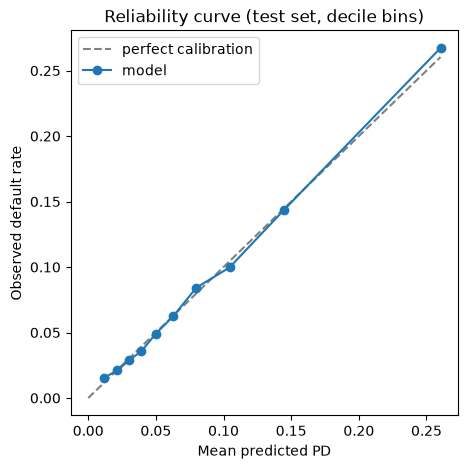

In [11]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, table["predicted"].max()], [0, table["predicted"].max()],
        "--", color="grey", label="perfect calibration")
ax.plot(table["predicted"], table["observed"], "o-", label="model")
ax.set_xlabel("Mean predicted PD")
ax.set_ylabel("Observed default rate")
ax.set_title("Reliability curve (test set, decile bins)")
ax.legend();

## Calibration

| | value |
|---|---|
| Brier | 0.06830 |
| Brier of always predicting the base rate | 0.07421 |
| Brier skill score | 0.0797 |

**Brier alone is as misleading as accuracy was.** Predicting the base rate for every applicant scores `b(1-b)` = 0.0742 — a small, respectable-looking number from a model that knows nothing. Only the skill score, measured against that reference, says anything.

**The probabilities are close to right.** Across decile bins the largest gap between predicted and observed default rate is 0.69 percentage points, and most bins are inside 0.5pp. Decomposing Brier into reliability - resolution + uncertainty puts miscalibration at roughly 0.000012 against 0.0742 of irreducible uncertainty: about 0.02% of the baseline. (Computed from the decile table, so resolution is understated and the figures are indicative.)

**A low skill score here is not a calibration failure.** Of the 0.0742 total, the model explains about 0.0053. The rest is irreducible: whether one individual defaults is mostly not predictable from an application form. This is the honest ceiling, not a defect to tune away.

**The model is slightly optimistic in the riskiest decile** — 26.03% predicted against 26.73% observed, roughly 43 more defaults than expected among 6,151 applicants. Optimism is the costlier direction: pessimism forgoes margin on good applicants, optimism under-provisions against the worst ones. Carried into B8 and into the model card.

**Limitation.** Decile bins compress the top of the distribution: nine points sit below 0.15 and the tenth averages everything from 0.15 to the maximum. The top decile should be split further before the calibration there is trusted — deferred to B11.

**Calibration vs discrimination, stated once.** Discrimination (B6) asks whether the ordering is right and cannot see any monotone rescaling of the scores. Calibration asks whether a predicted 5% defaults 5% of the time. A model can be excellent at one and useless at the other: halving every PD leaves AUC, Gini and KS bit-identical while halving every expected-loss figure. Lending needs both — ranking to decide who to approve, calibration to decide what to charge and what to provision.